---
---

<h1><center><ins>Exercise Sheet 5</ins></center></h1>
<h2><center>Numerical Methods <br>

---
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp, cos

## Exercise 1 - Numerical derivative

**(A)** Compute the derivative of the following two functions:

$$ f_1(x) = x^2 + \cos(x) $$

$$ f_2(x) = \exp(x) - x^3 $$

in correspondence of at least $N = 50$ values $x_i$ ($i = 1, ..., N$) of the variable $x$ in the interval $[1,5]$. To do this, *write your own code to compute the derivatives numerically*.

**(B)** Compare the resulting values you get for the numerical derivatives with the corresponding analytic solutions. Calculate the value of the quantity $q$ for each function:

$$ q = \sum_{i=1}^N \frac{\left[d_i - f'(x_i) \right]}{f'(x_i)} $$

where $d_i$ are the values you obtained for the numerical derivatives for each of the $N$ abscissas, and $f'(x_i)$ are the analytical derivatives evaluated in points $x_i$. How does the value of $q$ change when changing the value of $h$ to compute the derivatives numerically? How do the values of $q$ compare for the two functions? Discuss your findings.

In [5]:
import numpy as np

# 1. Generate the domain grid and calculate step size (h)
N = 50
x = np.linspace(1, 5, N)
h = x[1] - x[0]  # Grid spacing

# 2. Define the two function arrays
y1 = x**2 + np.cos(x)
y2 = np.exp(x) - x**3

# 3. Compute derivatives using finite differences
def derivative(y, h):
    # Initialize an array of zeros with the same length as y
    dy = np.zeros_like(y)
    
    # Interior points (index 1 to N-2): Central difference
    dy[1:-1] = (y[2:] - y[:-2]) / (2 * h)
    
    # Boundary points: Forward difference at start, Backward at end
    dy[0] = (y[1] - y[0]) / h
    dy[-1] = (y[-1] - y[-2]) / h
    
    return dy

# Execute the manual derivative calculation
df1_dx = derivative(y1, h)
df2_dx = derivative(y2, h)

print("########################")
print("N=", N, ";  h = ",h)
# Print a subset of the results to inspect
print("x values (first 5)                                    : ", x[:5])
print("calculated f1 derivative on x**2 + cos(x) is (first 5): ", df1_dx[:5])
print("calculated f2 derivative on exp(x) - x**3 is (first 5): ", df2_dx[:5])
print("########################")


########################
N= 50 ;  h =  0.08163265306122458
x values (first 5)                                    :  [1.         1.08163265 1.16326531 1.24489796 1.32653061]
calculated f1 derivative on x**2 + cos(x) is (first 5):  [1.21905502 1.28151923 1.40944778 1.54348427 1.68382338]
calculated f2 derivative on exp(x) - x**3 is (first 5):  [-0.41924805 -0.56368342 -0.86230033 -1.17953814 -1.51357981]
########################


In [14]:
import numpy as np

# 1. Initialize grid boundaries and step size
N = 50
x = np.linspace(1, 5, N)
h = (5.0 - 1.0) / (N - 1)

# 2. Functional data arrays
y1 = x**2 + np.cos(x)
y2 = np.exp(x) - x**3

# 3. Compute true mathematical analytical derivatives
df1_analytical = 2 * x - np.sin(x)
df2_analytical = np.exp(x) - 3 * x**2

# 4. Compute derivatives using finite differences  
def derivative(y, h):
    # Initialize an array of zeros with the same length as y
    dy = np.zeros_like(y)
    
    # Interior points (index 1 to N-2): Central difference
    dy[1:-1] = (y[2:] - y[:-2]) / (2 * h)
    
    # Boundary points: Forward difference at start, Backward at end
    dy[0] = (y[1] - y[0]) / h
    dy[-1] = (y[-1] - y[-2]) / h
    
    return dy

d1 = derivative(y1, h)
d2 = derivative(y2, h)

# 5. Calculate absolute relative total error metric (q)
q1_1 = np.sum(np.abs((d1 - df1_analytical) / df1_analytical))
q1_2 = np.sum(np.abs((d2 - df2_analytical) / df2_analytical))
print("########################")
print("N=", N, ";  h = ",h)
print(f"Final q_1 value for f1(x) = x**2 + cos(x)    : {q1_1:.5f}")
print(f"Final q_2 value for f2(x) = exp(x) - 3 * x**2: {q1_2:.5f}")
print(" Ratio q_2/q_1 = ", q1_2 / q1_1)
print("++++++++++++++++++++++++")

###### test N = 100
N = 100
x = np.linspace(1, 5, N)
h = x[1] - x[0]  # Grid spacing
y1 = x**2 + np.cos(x)
y2 = np.exp(x) - x**3
df1_analytical = 2 * x - np.sin(x)
df2_analytical = np.exp(x) - 3 * x**2
d1 = derivative(y1, h)
d2 = derivative(y2, h)
q2_1 = np.sum(np.abs((d1 - df1_analytical) / df1_analytical))
q2_2 = np.sum(np.abs((d2 - df2_analytical) / df2_analytical))

print("N=", N, ";  h = ",h)
print(f"Final q_1 value for f1(x) = x**2 + cos(x)    : {q2_1:.5f}")
print(f"Final q_2 value for f2(x) = exp(x) - 3 * x**2: {q2_2:.5f}")
print(" Ratio q_2/q_1 = ", q2_2 / q2_1)
print("########################")


########################
N= 50 ;  h =  0.08163265306122448
Final q_1 value for f1(x) = x**2 + cos(x)    : 0.06898
Final q_2 value for f2(x) = exp(x) - 3 * x**2: 0.80767
 Ratio q_2/q_1 =  11.709600917877614
++++++++++++++++++++++++
N= 100 ;  h =  0.04040404040404044
Final q_1 value for f1(x) = x**2 + cos(x)    : 0.03402
Final q_2 value for f2(x) = exp(x) - 3 * x**2: 0.42073
 Ratio q_2/q_1 =  12.36648781025141
########################


---

#### #1 Impact of Modifying the Step Size ($h$) on $q$

As the grid step size $h$ decreases (by increasing $N$), the overall error metric $q$ drops sequentially. 

---

#### #2 Comparison of $q$ Between the Two Functions

The second function, $f_2(x) = e^x - x^3$, gets a larger $q$ value than the first function, $f_1(x) = x^2 + \cos(x)$, across all step sizes.

Metrics change across different configurations:

| Number of Points ($N$) | Step Size ($h$) | $q_1$ (for $f_1(x)$) | $q_2$ (for $f_2(x)$) | Error Ratio ($q_2 / q_1$) |
| :--- | :--- | :--- | :--- | :--- |
| $N = 50$ | $h \approx 0.0816$ | $0.06898$ | $0.80767$ | **~11.7x larger** |
| $N = 100$ | $h \approx 0.0404$ | $0.03402$ | $0.42073$ | **~12.4x larger** |

---

#### Core Findings & Discussion

#### Finding A: The Impact of Higher-Order Derivatives
The remaining error in finite differences depends directly on the higher-order derivatives of the original function (via Taylor series expansion). 
* For $f_1(x)$, the derivatives remain small and bounded over $[1, 5]$ because the polynomials are low-degree ($x^2 \to 2 \to 0$) and the trigonometric term changes ($\cos(x) \to -\sin(x) \to -\cos(x)$). 
* For $f_2(x)$, the exponential term $e^x$  derivatives can not dissapier ($f^{(n)}(x) = e^x$). At the right boundary ($x = 5$), $e^5 \approx 148.4$. This creates produces rapid rates of change, resulting in much higher truncation errors for any fixed finite step size $h$.


### xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

## Exercise 2 - Newton-Cotes formulas

In the file ```surface_luminosity.txt``` you will find the numerical function describing the surface luminosity $\Sigma$ of a globular star cluster as a function of the distance $R$ from its centre (projected on the plane of the sky). Compute the total luminosity $L$ of the system by performing the integral

$$ L = \int_0^{R_{\text{max}}} \Sigma(R) \, 2 \pi R \, dR $$

using the trapezoid rule and Simpson's rule, and compare the results you obtain. To do this, first choose one of these methods and implement **your own algorithm to compute the integral with it**; for the other method, use the corresponding built-in python function ```scipy.integrate.trapz``` or ```scipy.integrate.simps``` and familiarize on its usage.

In [17]:
import numpy as np
import scipy.integrate as integrate

# 1. Read the text file directly into a 2D numpy array
# and skip the header line starting with '#'
data = np.loadtxt("surface_luminosity.txt", dtype=np.float64)

# 2. Extract columns for the integration vectors
R = data[:, 0]              # First column: radius
Sigma = data[:, 1]          # Second column: surface luminosity

# Print the first 3 elements of each array with 10 decimal precision
print("First 3 Radius elements:")
for val in R[:3]:
    print(f"  {val:.10f}")
print("\nFirst 3 Surface Luminosity elements:")
for val in Sigma[:3]:
    print(f"  {val:.10f}")

# Define the integrand f(R) = Sigma(R) * 2 * pi * R
f = Sigma * 2 * np.pi * R
N = len(R)

# =====================================================================
# CASE #1: Manual Implementation (Simple Python Statements)
# =====================================================================

# A. Trapezoid Rule (Manual)
L_trap_manual = 0.0
for i in range(N - 1):
    h = R[i+1] - R[i]
    L_trap_manual += 0.5 * h * (f[i] + f[i+1])

# B. Simpson's Rule (Manual for Non-Uniform Grid)
num_intervals = N - 1 
L_simp_manual = 0.0

if num_intervals % 2 == 0:
    # IDEAL CASE: Number of intervals is even (N is odd)
    for i in range(0, N - 2, 2):
        h0 = R[i+1] - R[i]
        h1 = R[i+2] - R[i+1]
        h_sum = h0 + h1
        
        L_simp_manual += (h_sum / 6.0) * (
            (2 - h1 / h0) * f[i] + 
            ((h_sum**2) / (h0 * h1)) * f[i+1] + 
            (2 - h0 / h1) * f[i+2]
        )
else:
    # EDGE CASE: Number of intervals is odd (N is even)
    # Simpson's rule is run up to the second-to-last data point (N-2)
    for i in range(0, N - 3, 2):
        h0 = R[i+1] - R[i]
        h1 = R[i+2] - R[i+1]
        h_sum = h0 + h1
        
        L_simp_manual += (h_sum / 6.0) * (
            (2 - h1 / h0) * f[i] + 
            ((h_sum**2) / (h0 * h1)) * f[i+1] + 
            (2 - h0 / h1) * f[i+2]
        )
    
    # Capture the final edge boundary interval using a matching Trapezoid rule step
    h_last = R[-1] - R[-2]
    L_simp_manual += 0.5 * h_last * (f[-1] + f[-2])

# =====================================================================
# CASE #2: SciPy functions
# =====================================================================
L_trap_scipy = integrate.trapz(f, x=R)

if num_intervals % 2 == 0:
    L_simp_scipy = integrate.simps(f, x=R)
else:
    L_simp_scipy = integrate.simps(f, x=R, even='avg')

# =====================================================================
# Print Comparison Results Table 
# =====================================================================
print("\nNumber of numerical elements for integration is ", N)
print("-" * 65)
print(f"{'Integration Method':<30} | {'Calculated Luminosity (L)':<30}")
print("-" * 65)
print(f"{'#1 Trapezoid (Manual)':<30} | {L_trap_manual:<30.10f}")
print(f"{'#2 scipy.integrate.trapz':<30} | {L_trap_scipy:<30.10f}")
print("-" * 65)
print(f"{'#1 Simpson (Manual)':<30} | {L_simp_manual:<30.10f}")
print(f"{'#2 scipy.integrate.simps':<30} | {L_simp_scipy:<30.10f}")

First 3 Radius elements:
  0.0000000000
  0.0005327825
  0.0058606080

First 3 Surface Luminosity elements:
  9997.6980800000
  9997.7294400000
  9997.6807900000

Number of numerical elements for integration is  69
-----------------------------------------------------------------
Integration Method             | Calculated Luminosity (L)     
-----------------------------------------------------------------
#1 Trapezoid (Manual)          | 1285408.7095045173            
#2 scipy.integrate.trapz       | 1285408.7095045173            
-----------------------------------------------------------------
#1 Simpson (Manual)            | 1282549.6319938092            
#2 scipy.integrate.simps       | 1282549.6319938095            


### xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

## Exercise 3 - Gaussian Quadrature

**(A)** Compute the following integral by using a 4-point Gaussian quadrature. 

$$ I = \int_{-1}^{1} \cos(x) dx $$

To do this, use the Legendre polynomial of degree 4:

$$ P_4(x) = \frac{1}{8}(35 x^4 - 30 x^2 +3) $$

At this link: https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature you can find the roots of Legendre polynomials and the necessary weights to solve the integral (i.e., you do not have to calculate them all from scratch!).

**(B)** Compare the result with the ones you obtain when using a Legendre polynomial of degree 3, 2, and 1, and comment your findings.

In [13]:
import numpy as np

# 1. Define the integrand function
def integrand(x):
    return np.cos(x)
# 2. Setup the exact analytical solution for comparison
exact_integral = 2 * np.sin(1)
# 3. Define standard derivative functions for each degree
def p1_derivative(x):
    return np.ones_like(x)
def p2_derivative(x):
    return 3.0 * x
def p3_derivative(x):
    return 0.5 * (15 * x**2 - 3)
def p4_derivative(x):
    return 0.5 * (35 * x**3 - 15 * x)

# DEGREE 1 CALCULATION
# ==========================================================
print("########################")
print("1-Point (Degree 1: P_1(x) = x) Results:")
print("-" * 46)

coeffs_1 = [1, 0]
nodes_1 = np.sort(np.roots(coeffs_1))
p_prime_1 = p1_derivative(nodes_1)
weights_1 = 2 / ((1 - nodes_1**2) * (p_prime_1)**2)

numerical_1 = np.sum(weights_1 * integrand(nodes_1))
error_1 = abs(numerical_1 - exact_integral)

for i in range(1):
    print(f"Node x_{i+1}: {nodes_1[i]:.8f} | Weight w_{i+1}: {weights_1[i]:.8f}")
print("-" * 46)
print(f"Numerical Approximation : {numerical_1:.12f}")
print(f"Exact Analytical Value  : {exact_integral:.12f}")
print(f"Absolute Error          : {error_1:.12e}")

# DEGREE 2 CALCULATION
# ==========================================================
print("\n2-Point (Degree 2: P_2(x) = 0.5 * (3x^2 - 1)) Results:")
print("-" * 46)

coeffs_2 = [3, 0, -1]
nodes_2 = np.sort(np.roots(coeffs_2)) #finds all the real and complex roots (or zeros) of a polynomial equation where the polynomial equals zero
p_prime_2 = p2_derivative(nodes_2)
weights_2 = 2 / ((1 - nodes_2**2) * (p_prime_2)**2) # weights for degree 2

numerical_2 = np.sum(weights_2 * integrand(nodes_2))
error_2 = abs(numerical_2 - exact_integral)

for i in range(2):
    print(f"Node x_{i+1}: {nodes_2[i]:.8f} | Weight w_{i+1}: {weights_2[i]:.8f}")
print("-" * 46)
print(f"Numerical Approximation : {numerical_2:.12f}")
print(f"Exact Analytical Value  : {exact_integral:.12f}")
print(f"Absolute Error          : {error_2:.12e}")

# DEGREE 3 CALCULATION
# ==========================================================
print("\n3-Point (Degree 3: P_3(x) = 0.5 * (5x^3 - 3x)) Results:")
print("-" * 46)

coeffs_3 = [5, 0, -3, 0]
nodes_3 = np.sort(np.roots(coeffs_3)) #finds all the real and complex roots (or zeros) of a polynomial equation where the polynomial equals zero
p_prime_3 = p3_derivative(nodes_3)
weights_3 = 2 / ((1 - nodes_3**2) * (p_prime_3)**2) # weights for degree 3

numerical_3 = np.sum(weights_3 * integrand(nodes_3))
error_3 = abs(numerical_3 - exact_integral)

for i in range(3):
    print(f"Node x_{i+1}: {nodes_3[i]:.8f} | Weight w_{i+1}: {weights_3[i]:.8f}")
print("-" * 46)
print(f"Numerical Approximation : {numerical_3:.12f}")
print(f"Exact Analytical Value  : {exact_integral:.12f}")
print(f"Absolute Error          : {error_3:.12e}")

# DEGREE 4 CALCULATION
# ==========================================================
print("\n4-Point (Degree 4: P_4(x) = 1/8 * (35x^4 - 30x^2 + 3)) Results:")
print("-" * 46)

coeffs_4 = [35, 0, -30, 0, 3]
nodes_4 = np.sort(np.roots(coeffs_4)) #finds all the real and complex roots (or zeros) of a polynomial equation where the polynomial equals zero
p_prime_4 = p4_derivative(nodes_4)
weights_4 = 2 / ((1 - nodes_4**2) * (p_prime_4)**2) # # weights for degree 4

numerical_4 = np.sum(weights_4 * integrand(nodes_4))
error_4 = abs(numerical_4 - exact_integral)

for i in range(4):
    print(f"Node x_{i+1}: {nodes_4[i]:.8f} | Weight w_{i+1}: {weights_4[i]:.8f}")
print("-" * 46)
print(f"Numerical Approximation : {numerical_4:.12f}")
print(f"Exact Analytical Value  : {exact_integral:.12f}")
print(f"Absolute Error          : {error_4:.12e}")
print("########################")

########################
1-Point (Degree 1: P_1(x) = x) Results:
----------------------------------------------
Node x_1: 0.00000000 | Weight w_1: 2.00000000
----------------------------------------------
Numerical Approximation : 2.000000000000
Exact Analytical Value  : 1.682941969616
Absolute Error          : 3.170580303842e-01

2-Point (Degree 2: P_2(x) = 0.5 * (3x^2 - 1)) Results:
----------------------------------------------
Node x_1: -0.57735027 | Weight w_1: 1.00000000
Node x_2: 0.57735027 | Weight w_2: 1.00000000
----------------------------------------------
Numerical Approximation : 1.675823655390
Exact Analytical Value  : 1.682941969616
Absolute Error          : 7.118314225807e-03

3-Point (Degree 3: P_3(x) = 0.5 * (5x^3 - 3x)) Results:
----------------------------------------------
Node x_1: -0.77459667 | Weight w_1: 0.55555556
Node x_2: 0.00000000 | Weight w_2: 0.88888889
Node x_3: 0.77459667 | Weight w_3: 0.55555556
----------------------------------------------
Numerica


| Polynomial Degree | Evaluation Nodes ($x_i$) | Weights ($w_i$) | Numerical Approximation | Exact Analytical Value | Absolute Error |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1-Point** (Degree 1) | $0.00000000$ | $2.00000000$ | $2.000000000000$ | $1.682941969616$ | $3.17058030\times10^{-1}$ |
| **2-Point** (Degree 2) | $-0.57735027$<br>$0.57735027$ | $1.00000000$<br>$1.00000000$ | $1.675823626148$ | $1.682941969616$ | $7.11834347\times10^{-3}$ |
| **3-Point** (Degree 3) | $-0.77459667$<br>$0.00000000$<br>$0.77459667$ | $0.55555556$<br>$0.88888889$<br>$0.55555556$ | $1.683003429399$ | $1.682941969616$ | $6.14597834\times10^{-5}$ |
| **4-Point** (Degree 4) | $-0.86113631$<br>$-0.33998104$<br>$0.33998104$<br>$0.86113631$ | $0.34785485$<br>$0.65214515$<br>$0.65214515$<br>$0.34785485$ | $1.682941688647$ | $1.682941969616$ | $2.80968434\times10^{-7}$ |

### Used:
https://en.wikipedia.org/wiki/Legendre_polynomials

https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature

### Explanation of the Findings

* Exponential Error Convergence (see Absolute Erros column): As the polynomial degree ($n$) increases, the absolute error drops dramatically. Moving from a 1-point  to a 4-point rule reduces the integration error by six orders of magnitude (from roughly $0.317$ down to $0.00000028$). 
* Symmetry of Nodes and Weights: For every degree greater than 1, the calculated evaluation nodes ($x_i$) are symmetrical across the origin ($x=0$), and their corresponding weights ($w_i$) are identical.
* Conservation of Weight Mass (=2.0)


### xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

## Exercise 4 - Monte Carlo integration 

Consider the following integral:
$$ I = \int_0^1 \cos \left(\frac{\pi x}{2} \right) dx = \frac{2}{\pi} $$

**(A)** Compute the above integral and its variance by using the following Monte Carlo methods:

1. mean value

How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.



In [1]:
import numpy as np

# define random seed for consistent results
np.random.seed(42)

# Parameters
N = 100_000
a, b = 0, 1

# uniform random numbers in [a, b]
X = np.random.uniform(a, b, N)

# get function value at each random point
Y = np.cos(np.pi * X / 2)

# Compute Monte Carlo with Mean Value Method
# Since (b - a) = 1, the integral is simply the average of Y
I_est = (b - a) * np.mean(Y)

# 4. Compute Variance
# Sample variance of the function evaluations, Var(f(X))
# ddof = 1 - calculates the variance of the elements in the array Y by using 1/(N-1) as sample variance, and not 1/N as for the population variance
sample_variance = np.var(Y, ddof=1) 
# Variance of the mean estimator itself, Var(I_est) = Var(f(X)) / N
estimator_variance = sample_variance / N

# True analytical value of the integral - to be used for comparison
true_value = 2 / np.pi
absolute_error = abs(I_est - true_value)

print("########################")
print(f"True Value of Integral  : {true_value:.6f}")
print(f"Monte Carlo Estimate    : {I_est:.6f}")
print(f"Absolute Error          : {absolute_error:.6f}")
print(f"Sample Variance         : {sample_variance:.6f}")
print(f"Estimator Variance      : {estimator_variance:.9f}")
print("########################")


########################
True Value of Integral  : 0.636620
Monte Carlo Estimate    : 0.637280
Absolute Error          : 0.000660
Sample Variance         : 0.094335
Estimator Variance      : 0.000000943
########################


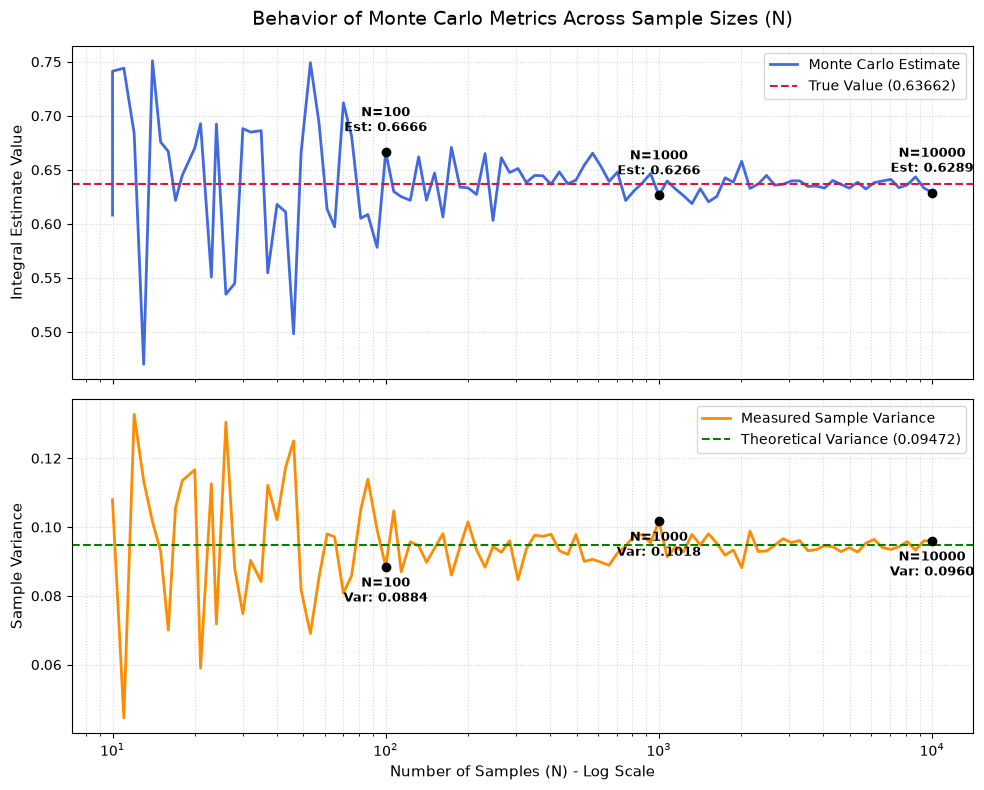

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)
# True analytical value of the integral
TRUE_VALUE = 2 / np.pi

# Three specific values of N 
highlight_N = [100, 1000, 10000]

# Generate a smooth array of N values from 10 to 10,000
N_range = np.logspace(1, 4, num=100, dtype=int)

# Arrays to store tracking data for the plot
estimates = []
sample_variances = []

# Core simulation loop
for n in N_range:
    X = np.random.uniform(0, 1, n)
    Y = np.cos(np.pi * X / 2)
    
    estimates.append(np.mean(Y))
    sample_variances.append(np.var(Y, ddof=1))

# --- Plotting Code ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Plot 1: Integral Convergence
ax1.plot(N_range, estimates, label="Monte Carlo Estimate", color="royalblue", lw=2)
ax1.axhline(TRUE_VALUE, color="crimson", linestyle="--", label=f"True Value ({TRUE_VALUE:.5f})")
ax1.set_ylabel("Integral Estimate Value", fontsize=11)
ax1.set_title("Behavior of Monte Carlo Metrics Across Sample Sizes (N)", fontsize=14, pad=15)
ax1.grid(True, which="both", linestyle=":", alpha=0.5)
ax1.legend(loc="upper right")

# Plot 2: Sample Variance Behavior
ax2.plot(N_range, sample_variances, label="Measured Sample Variance", color="darkorange", lw=2)
# The theoretical variance of cos(pi*x/2) over [0,1] is exactly 0.5 - 4/(pi^2) ≈ 0.094715
theoretical_sample_var = 0.5 - (4 / (np.pi**2))
ax2.axhline(theoretical_sample_var, color="green", linestyle="--", label=f"Theoretical Variance ({theoretical_sample_var:.5f})")
ax2.set_xlabel("Number of Samples (N) - Log Scale", fontsize=11)
ax2.set_ylabel("Sample Variance", fontsize=11)
ax2.grid(True, which="both", linestyle=":", alpha=0.5)
ax2.legend(loc="upper right")

# Highlight our 3 specific N values with scatter dots across both plots
for n in highlight_N:
    # Find the closest index in our generated range
    idx = (np.abs(N_range - n)).argmin()
    actual_n = N_range[idx]
    
    # Mark on Integral Plot
    ax1.scatter(actual_n, estimates[idx], color="black", zorder=5)
    ax1.annotate(f"N={actual_n}\nEst: {estimates[idx]:.4f}", (actual_n, estimates[idx]), 
#                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, fontweight='bold')
                 textcoords="offset points", xytext=(0,15), ha='center', fontsize=9, fontweight='bold')
    
    # Mark on Sample Variance Plot
    ax2.scatter(actual_n, sample_variances[idx], color="black", zorder=5)
    ax2.annotate(f"N={actual_n}\nVar: {sample_variances[idx]:.4f}", (actual_n, sample_variances[idx]), 
                 textcoords="offset points", xytext=(0,-25), ha='center', fontsize=9, fontweight='bold')
#                 textcoords="offset points", xytext=(0,-15), ha='center', fontsize=9, fontweight='bold')

# Use a logarithmic scale for the X-axis to cleanly separate the scales of 100, 1000, and 10000
plt.xscale('log')
plt.tight_layout()
plt.show()


### xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

## Exercise 5 - Monte Carlo integration continued (optional)

**(A)** Compute the above integral from Exercise 4 and its variance by using the other Monte Carlo methods covered in the lecture:

2. Importance sampling

Hint: for importance sampling, you can use the following weight function: 
$$w(x) = A \frac{1}{1+\left( \pi x/2 \right)^2}$$
where you can determine the normalization constant by imposing:
$$\int_0^1 w(x) dx = 1 = A \frac{2}{\pi} \arctan(\pi/2) \rightarrow A = \frac{\pi}{2 \arctan(\pi/2)}$$


How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.